In [3]:
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.exceptions import ConvergenceWarning

from outils import load_subject, decode_time, chance_control, plot_curves

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # MLP / saga iteration warnings

SUBJECTS = ["sub-006", "sub-008", "sub-009", "sub-013", "sub-014", "sub-015"]

DATA_FILE = "/Users/rafaela.dsp/Desktop/EPFL/MA1/Machine Learning/ML_EEG_FoodImages/epoch_data_6sujets.nc"
SFREQ = 256  # samples per second

petit = xr.load_dataset(DATA_FILE)
SUBJECTS = petit.recording.values
print(SUBJECTS)

['sub-006_task-categorisation' 'sub-008_task-categorisation'
 'sub-009_task-categorisation' 'sub-013_task-categorisation'
 'sub-014_task-categorisation' 'sub-015_task-categorisation']


In [4]:
def health_data(petit, name):
    """Return X (trials, electrodes, time points), y (1 = healthy, 0 = unhealthy) and time in seconds."""
    s = petit.sel(recording=name)
    mask = (s.event_name.values == "display") & (s.event_type.values == "health")
    X = s["data"].values[mask]
    y = (s.resp_choice.values[mask] == "Yes").astype(int)
    time = s.sample.values / SFREQ
    return X, y, time


Replicate the ERP analysis of the paper (Figure 2A): healthy vs. unhealthy ERPs at occipital electrodes (Oz, O1, O2, Iz), 120 Healthy? trials per subject, 6 subjects.

In [27]:
X, y, time = health_data(petit, SUBJECTS[0])
print(X.shape, y.sum(), np.abs(X).mean())

print('Electrodes names :', petit.channel.values)

electO = np.isin(petit.channel.values, ["Oz", "O1", "O2", "Iz"])
print('Number of electrodes', electO.sum())

X_occ = X[:, electO, :]
mean_electO = X_occ.mean(axis=1)

mean_electO *= 1e6  # convert to microvolts
print('Mean amplitude (microvolts) for Oz, O1, O2, Iz:', mean_electO.mean())

print(np.abs(mean_electO).mean())

healthy = (y == 1)
print(healthy[:10])
X_healthy = mean_electO[healthy, :]
print(X_healthy.shape)   # (58, 705)
erp_healthy = X_healthy.mean(axis=0)
print(erp_healthy.shape)   # (705,)


unhealthy = (y == 0)
X_unhealthy = mean_electO[unhealthy, :]
print(X_unhealthy.shape)   
erp_unhealthy = X_unhealthy.mean(axis=0)


(120, 64, 705) 58 4.5175875e-06
Electrodes names : ['Fp1' 'AF7' 'AF3' 'F1' 'F3' 'F5' 'F7' 'FT7' 'FC5' 'FC3' 'FC1' 'C1' 'C3'
 'C5' 'T7' 'TP7' 'CP5' 'CP3' 'CP1' 'P1' 'P3' 'P5' 'P7' 'P9' 'PO7' 'PO3'
 'O1' 'Iz' 'Oz' 'POz' 'Pz' 'CPz' 'Fpz' 'Fp2' 'AF8' 'AF4' 'AFz' 'Fz' 'F2'
 'F4' 'F6' 'F8' 'FT8' 'FC6' 'FC4' 'FC2' 'FCz' 'Cz' 'C2' 'C4' 'C6' 'T8'
 'TP8' 'CP6' 'CP4' 'CP2' 'P2' 'P4' 'P6' 'P8' 'P10' 'PO8' 'PO4' 'O2']
Number of electrodes 4
Mean amplitude (microvolts) for Oz, O1, O2, Iz: 0.3323325
4.934014
[ True  True  True  True False  True  True False  True  True]
(58, 705)
(705,)
(62, 705)


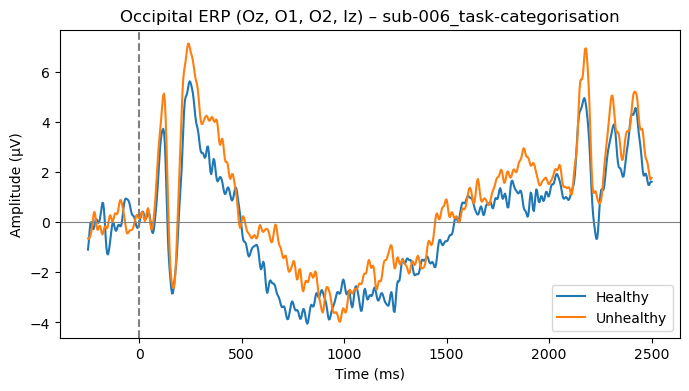

In [28]:
import matplotlib.pyplot as plt

t_ms = time * 1000

plt.figure(figsize=(8, 4))
plt.plot(t_ms, erp_healthy, label="Healthy")
plt.plot(t_ms, erp_unhealthy, label="Unhealthy")
plt.axhline(0, color="gray", lw=0.8)    # ligne du zéro
plt.axvline(0, color="gray", ls="--")   # apparition de l'image
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (µV)")
plt.title(f"Occipital ERP (Oz, O1, O2, Iz) – {SUBJECTS[0]}")
plt.legend()
plt.show()

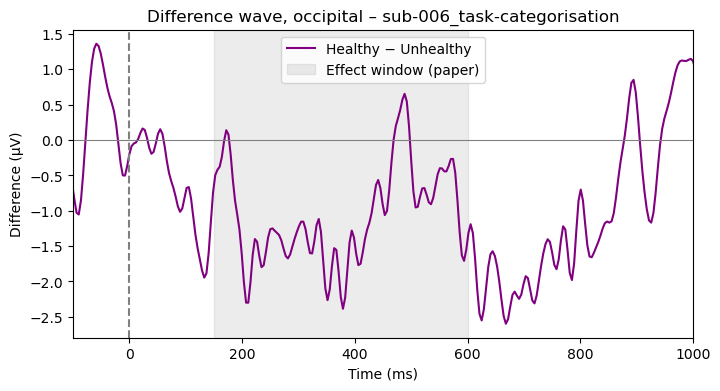

Mean difference 150–600 ms: -1.0780137 µV


In [29]:
diff = erp_healthy - erp_unhealthy

plt.figure(figsize=(8, 4))
plt.plot(t_ms, diff, color="purple", label="Healthy − Unhealthy")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", ls="--")
plt.axvspan(150, 600, color="gray", alpha=0.15, label="Effect window (paper)")
plt.xlim(-100, 1000)
plt.xlabel("Time (ms)")
plt.ylabel("Difference (µV)")
plt.title(f"Difference wave, occipital – {SUBJECTS[0]}")
plt.legend()
plt.show()

window = (t_ms >= 150) & (t_ms <= 600)
print("Mean difference 150–600 ms:", diff[window].mean(), "µV")

In [30]:
all_healthy = []
all_unhealthy = []

for name in SUBJECTS:
    X, y, time = health_data(petit, name)

    # Occipital ROI, in µV
    occ = X[:, electO, :].mean(axis=1) * 1e6        # (n_trials, 705)

    # ERP per condition
    all_healthy.append(occ[y == 1].mean(axis=0))     # (705,)
    all_unhealthy.append(occ[y == 0].mean(axis=0))   # (705,)

    print(name, "| healthy:", (y == 1).sum(), "| unhealthy:", (y == 0).sum())

all_healthy = np.array(all_healthy)       # (6, 705)
all_unhealthy = np.array(all_unhealthy)   # (6, 705)
all_diff = all_healthy - all_unhealthy    # (6, 705)
print(all_healthy.shape)

t_ms = time * 1000
n_sub = len(SUBJECTS)

sub-006_task-categorisation | healthy: 58 | unhealthy: 62
sub-008_task-categorisation | healthy: 75 | unhealthy: 45
sub-009_task-categorisation | healthy: 53 | unhealthy: 67
sub-013_task-categorisation | healthy: 73 | unhealthy: 47
sub-014_task-categorisation | healthy: 72 | unhealthy: 48
sub-015_task-categorisation | healthy: 54 | unhealthy: 66
(6, 705)


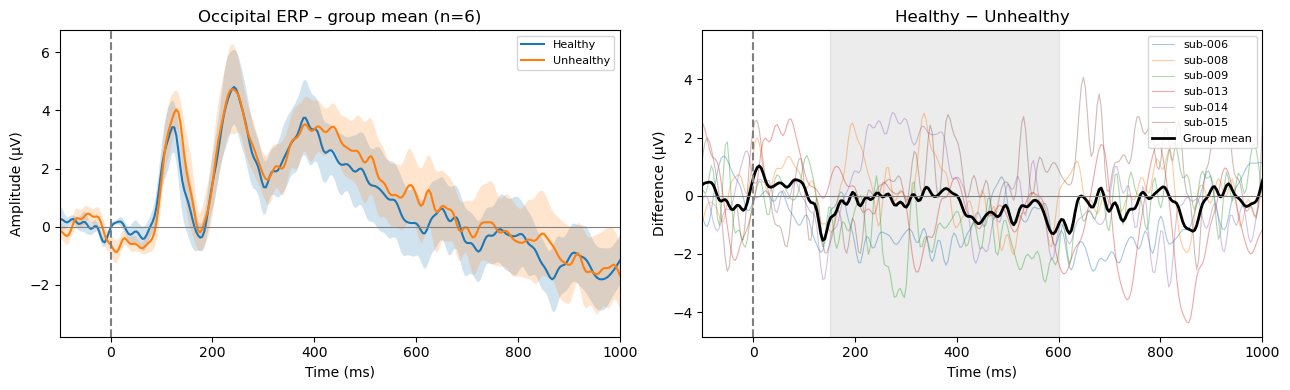

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: healthy vs unhealthy, group mean ± SEM
for data, label in [(all_healthy, "Healthy"), (all_unhealthy, "Unhealthy")]:
    m = data.mean(axis=0)
    sem = data.std(axis=0, ddof=1) / np.sqrt(n_sub)
    axes[0].plot(t_ms, m, label=label)
    axes[0].fill_between(t_ms, m - sem, m + sem, alpha=0.2)
axes[0].set_title(f"Occipital ERP – group mean (n={n_sub})")
axes[0].set_ylabel("Amplitude (µV)")

# Right: difference wave, each subject + group mean
for i, name in enumerate(SUBJECTS):
    axes[1].plot(t_ms, all_diff[i], lw=0.8, alpha=0.4, label=name[:7])
axes[1].plot(t_ms, all_diff.mean(axis=0), color="black", lw=2, label="Group mean")
axes[1].axvspan(150, 600, color="gray", alpha=0.15)
axes[1].set_title("Healthy − Unhealthy")
axes[1].set_ylabel("Difference (µV)")

for ax in axes:
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", ls="--")
    ax.set_xlim(-100, 1000)
    ax.set_xlabel("Time (ms)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("erp_healthy_occipital_6subjects.png", dpi=150)
plt.show()

In [32]:
window = (t_ms >= 150) & (t_ms <= 600)
mean_diff = all_diff[:, window].mean(axis=1)   # (6,)

for name, d in zip(SUBJECTS, mean_diff):
    print(f"{name[:7]}: {d:+.2f} µV")
print(f"Group: {mean_diff.mean():+.2f} µV | negative in {(mean_diff < 0).sum()}/{n_sub} subjects")

sub-006: -1.08 µV
sub-008: +0.03 µV
sub-009: -1.50 µV
sub-013: -0.45 µV
sub-014: +0.59 µV
sub-015: +0.42 µV
Group: -0.33 µV | negative in 3/6 subjects
